In [1]:
### standard libraries
import numpy as np
import matplotlib.pyplot as plt

### other libraries
import finufft

### my modules
from fast_volume_align_ot import utils, plots, transforms

In [2]:
def zero_pad_voxel_array_to_size(f, L):
    pass


def translate(array, tz, ty, tx):

    return np.roll(array, (tz, ty, tx), axis=(0,1,2))

(67, 67, 67)


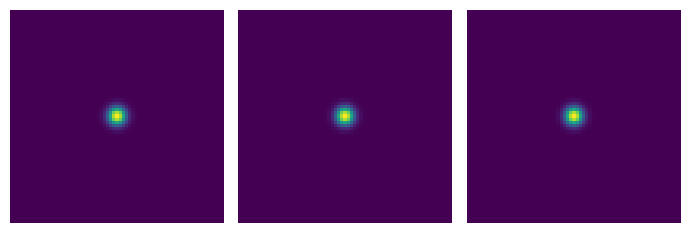

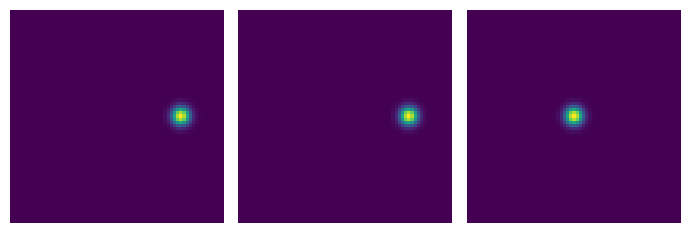

In [3]:
### generate initial volume
L = 37
sigma = 2
# f = utils.generate_3d_triangle_gaussian_shape(L, sigma)
f = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)

### zero pad to allow for shifting
w = 15
f = np.pad(f, pad_width=((w, w), (w, w), (w, w)))
print(f.shape)

plots.orthogonal_2D_projection_plot(f)

f_shift = translate(f, 0, 0, 20)
plots.orthogonal_2D_projection_plot(f_shift)

In [4]:
n_shifts = 20
shifts = np.arange(n_shifts+1)

dists_l2 = np.zeros(n_shifts+1)
dists_sw = np.zeros(n_shifts+1)

U = transforms.compute_projection_tensor_from_voxel_array(f)

for idx, s in enumerate(shifts):
    
    f_shift = translate(f, 0, 0, s)

    V = transforms.compute_projection_tensor_from_voxel_array(f_shift)
    
    d_sw = np.mean((U - V)**2, axis=1)
    d_sw = np.mean(d_sw, axis=0)
    d_sw = np.mean(d_sw)
    dists_sw[idx] = d_sw

    dists_l2[idx] = np.linalg.norm(f - f_shift)**2

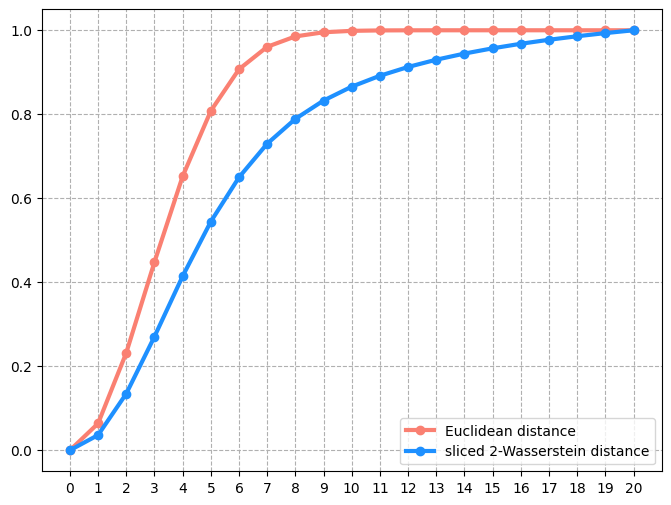

In [11]:
plt.figure(figsize=(8,6))

plt.plot(shifts, dists_l2 / np.amax(dists_l2), label='Euclidean distance', color='salmon', linewidth=3, linestyle='-', marker='o')
plt.plot(shifts, dists_sw / np.amax(dists_sw), label='sliced 2-Wasserstein distance', color='dodgerblue', linewidth=3, linestyle='-', marker='o')

plt.xticks(shifts)
plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

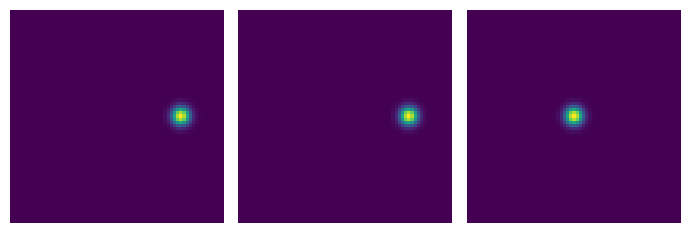

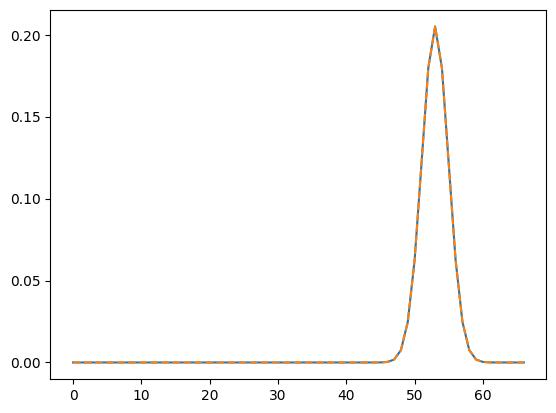

In [6]:
plots.orthogonal_2D_projection_plot(f_shift)

plt.plot(np.sum(f_shift, axis=(0, 1)))
plt.plot(V[0, :, 0], '--')